# Hvplot

Description
- A familiar and high-level API for data exploration and visualization that supports Dask, Pandas, Geopanda, Xarray, and more. Supports distributed plotting to lightening fast rendering


Resources:
- [Hvplot website] https://hvplot.holoviz.org/
- [Hvplot reference] https://hvplot.holoviz.org/reference/index.html
- [Examples] https://github.com/holoviz/hvplot/tree/v0.9.0/examples

NOTE:
- `rasterize=True` (Example 1) requires datashader.

## Example 1

Create a dask dataframe from numpy arrays and plot it

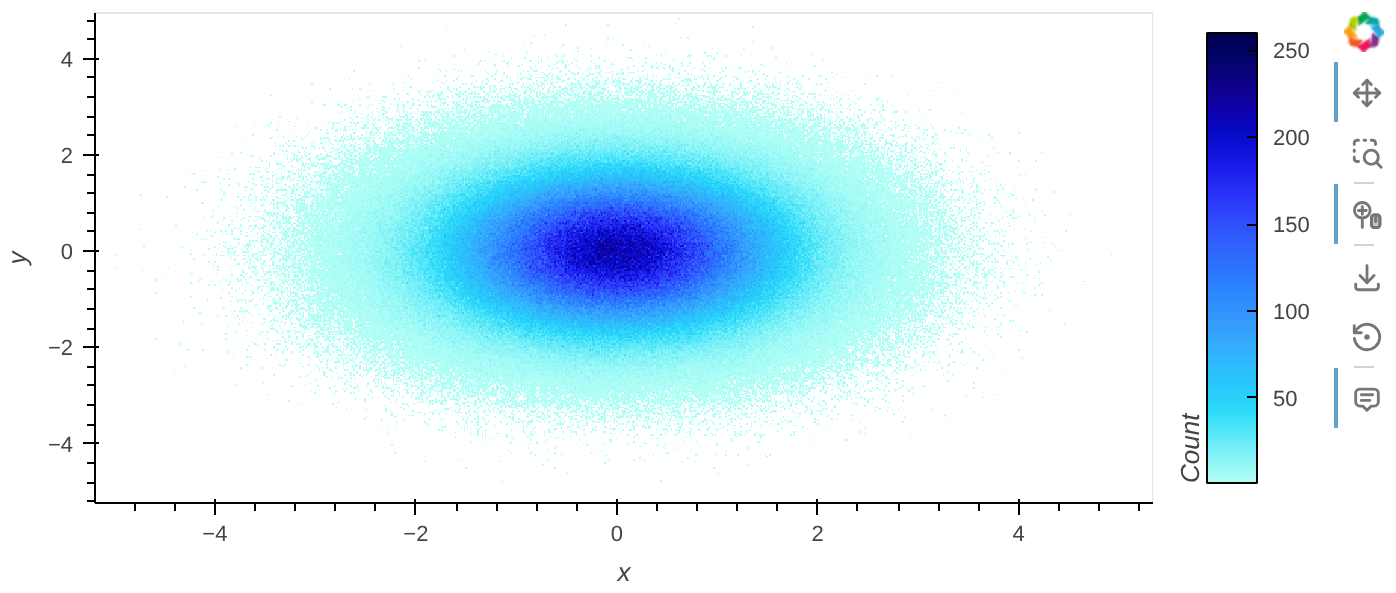

In [1]:
import numpy as np
import dask
import hvplot.dask

# Create Dask DataFrame with normally distributed data
df = dask.datasets.timeseries()
df['x'] = df['x'].map_partitions(lambda x: np.random.randn(len(x)))
df['y'] = df['y'].map_partitions(lambda x: np.random.randn(len(x)))

# Plot
df.hvplot.scatter(x='x', y='y', rasterize=True)

## Example 2

Plot a pandas dataframe

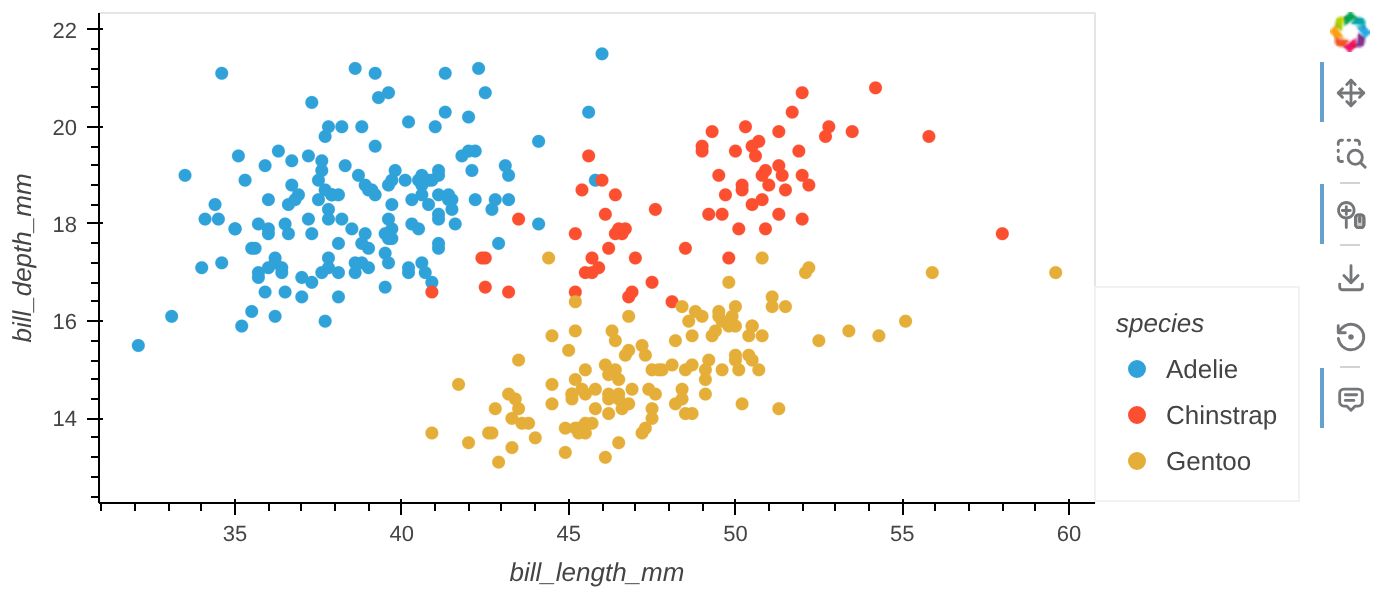

In [2]:
import hvplot.pandas
from bokeh.sampledata.penguins import data as df

df.hvplot.scatter(x='bill_length_mm', y='bill_depth_mm', by='species')

## Example 3

Plot a pandas dataframe

In [3]:
import numpy as np
import pandas as pd
import hvplot.pandas
idx = pd.date_range('1/1/2000', periods=1000)
df  = pd.DataFrame(np.random.randn(1000, 4), index=idx, columns=list('ABCD')).cumsum()
# Optional: hvplot.extension('matplotlibdf.hvplot()') or hvplot.extension('plotly')

plt = df.hvplot()

## Example 4

Plot a dask dataframe

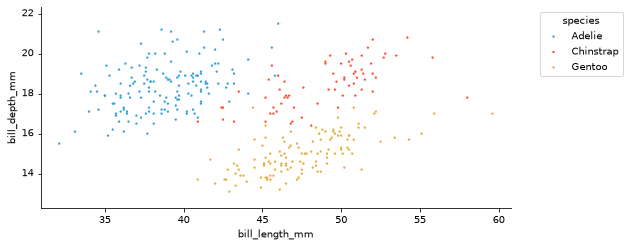

In [4]:
import dask
import hvplot.dask
from bokeh.sampledata.penguins import data as df
import matplotlib
# matplotlib.use("agg")  # optional: non-interactive backend for headless runs

hvplot.extension('matplotlib')

df_dask = dask.dataframe.from_pandas(df, npartitions=2)
df_dask.hvplot.scatter(x='bill_length_mm', y='bill_depth_mm', by='species')

## Example 5

Plot a pandas dataframe

In [5]:
import hvplot.pandas
import pandas as pd

df = pd.DataFrame(
    {
        "actual": [100, 150, 125, 140, 145, 135, 123],
        "forecast": [90, 160, 125, 150, 141, 141, 120],
        "numerical": [1.1, 1.9, 3.2, 3.8, 4.3, 5.0, 5.5],
        "date": pd.date_range("2022-01-03", "2022-01-09"),
        "string": ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
    },
)
line = df.hvplot.line(
    x="numerical",
    y=["actual", "forecast"],
    ylabel="value",
    legend="bottom",
    height=500,
    color=["steelblue", "teal"],
    alpha=0.7,
    line_width=5,
)